# Síntese — O que aprendemos e qual pergunta vem depois?

Este notebook reúne somente a rodada atual dos experimentos 03–08. Não ajusta novos modelos e não amplia grades após observar a validação. Separa duas questões: **o ganho de acrescentar informação e forma funcional** (03–06) e **o ganho de mudar o procedimento com os mesmos seis atributos** (06–08).

A comparação enxuta inclui regressão comum, Ridge, Bayesian Ridge e boosting. Após esta síntese, os padrões residuais motivaram testes controlados de idade, ano e contagens. A escolha final usa informação dos dez atributos brutos em onze colunas numéricas.

Protocolo: 5 folds × 5 repetições, semente 2026, previsões cortadas em [0, 5]. Buscas de Ridge e boosting usam três folds internos. As diferenças entre partições e repetições são descritivas, sem testes que suponham independência. A escolha entre famílias continua exploratória.

In [1]:
from pathlib import Path
from hashlib import sha256
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/train.csv').exists())
df = pd.read_csv(ROOT / 'data/train.csv')
y = df.stars.to_numpy(dtype=float)
folder = ROOT / 'results/rodada_atual'
runs, arrays = {}, {}
for prefix in ['03','04','05','06','07','08']:
    paths = list(folder.glob(prefix + '*.json'))
    assert len(paths) == 1, f'Execute o notebook {prefix} antes da síntese.'
    path = paths[0]
    run = json.loads(path.read_text(encoding='utf-8'))
    assert run['data_sha256'] == sha256((ROOT / 'data/train.csv').read_bytes()).hexdigest()
    source = json.loads((ROOT / 'notebooks' / (run['notebook'] + '.ipynb')).read_text(encoding='utf-8'))
    code_text = '\n'.join(''.join(cell['source']) for cell in source['cells'] if cell['cell_type'] == 'code')
    assert run['code_sha256'] == sha256(code_text.encode()).hexdigest(), f'Reexecute {prefix}: código alterado.'
    assert run['protocol'] == dict(n_splits=5, n_repeats=5, seed=2026, clip=True)
    runs[prefix] = run
    with np.load(path.with_suffix('.npz')) as archive:
        arrays[prefix] = {key: archive[key].copy() for key in archive.files}
    np.testing.assert_array_equal(arrays[prefix]['target'], y)
assert len({r['partitions_sha256'] for r in runs.values()}) == 1
assert len({json.dumps(r['versions'], sort_keys=True) for r in runs.values()}) == 1
print('Dados, código, protocolo, partições e versões compatíveis.')
display(pd.Series(runs['03']['versions'], name='Versão'))

def record(prefix, name):
    return next(r for r in runs[prefix]['records'] if r['name'] == name)

def prediction(prefix, name):
    return arrays[prefix][record(prefix, name)['array_key']]

# Referências repetidas em notebooks diferentes devem reproduzir a mesma previsão.
for a, na, b, nb in [('03','Duas médias','04','Duas médias'),
                      ('04','Duas médias + afinidade','05','Afinidade linear'),
                      ('05','Afinidade quadrática','06','Sem gênero explícito'),
                      ('06','Com gênero explícito','07','Regressão com gênero'),
                      ('07','Regressão com gênero','08','Regressão comum')]:
    np.testing.assert_allclose(prediction(a, na), prediction(b, nb), atol=1e-10)


Dados, código, protocolo, partições e versões compatíveis.


python     3.9.6
numpy      2.0.2
pandas     2.3.3
sklearn    1.6.1
Name: Versão, dtype: object

## 1 Construção progressiva da referência

Esta tabela varia os atributos, mantendo regressão sem penalização. Não atribuímos os ganhos à troca de algoritmo. O RMSE repetido usa todas as previsões OOF, não a média das previsões por linha.

In [2]:
progression = [('03','Constante'), ('03','Só usuário'), ('03','Só filme'),
               ('03','Duas médias'), ('04','Duas médias + afinidade'),
               ('05','Afinidade quadrática'), ('06','Com gênero explícito')]
def summarize(items):
    rows = []
    for prefix, name in items:
        r = record(prefix, name)
        rows.append({'modelo': name, 'RMSE OOF repetido': r['rmse_oof'],
                     'RMSE treino médio': np.mean(r['rmse_train']),
                     'menor RMSE por repetição': min(r['rmse_repeat']),
                     'maior RMSE por repetição': max(r['rmse_repeat']),
                     'diferença média validação − treino': np.mean(np.array(r['rmse_valid']) - r['rmse_train'])})
    return pd.DataFrame(rows).set_index('modelo')
display(summarize(progression).round(6))


,RMSE OOF repetido,RMSE treino médio,menor RMSE por repetição,maior RMSE por repetição,diferença média validação − treino
modelo,,,,,
Constante,1.165913,1.165393,1.165685,1.166238,0.000252
Só usuário,1.038440,1.037526,1.038146,1.038774,0.000555
Só filme,0.995403,0.994723,0.995143,0.995577,0.000400
Duas médias,0.839575,0.838483,0.839396,0.839826,0.000897
Duas médias + afinidade,0.660065,0.659117,0.659947,0.660174,0.000811
Afinidade quadrática,0.628989,0.627713,0.628529,0.629492,0.001084
Com gênero explícito,0.625036,0.623377,0.624681,0.625535,0.001491


## 2 Mesma informação e diferentes procedimentos

Os quatro procedimentos recebem as duas médias, afinidade, afinidade² e indicadores de comédia e drama. O erro de treino é otimista por construção. Uma distância maior até a validação sugere maior adaptação ao treino, mas deve ser lida junto ao erro absoluto de validação. Distância pequena, sozinha, não prova qualidade nem ausência de sobreajuste.

As buscas internas também variam entre procedimentos: comparamos receitas completas, não uma superioridade universal das famílias.

,RMSE OOF repetido,RMSE treino médio,menor RMSE por repetição,maior RMSE por repetição,diferença média validação − treino
modelo,,,,,
Com gênero explícito,0.625036,0.623377,0.624681,0.625535,0.001491
Ridge,0.625036,0.623378,0.624682,0.625536,0.001490
Bayesian Ridge,0.625074,0.623414,0.624721,0.625568,0.001494
Boosting,0.619248,0.565527,0.617608,0.620604,0.053584


,diferença RMSE OOF,partições com melhora,repetições com melhora
candidato,,,
Ridge,5.057826e-07,10,0
Bayesian Ridge,3.821385e-05,10,0
Boosting,-5.788156e-03,20,5


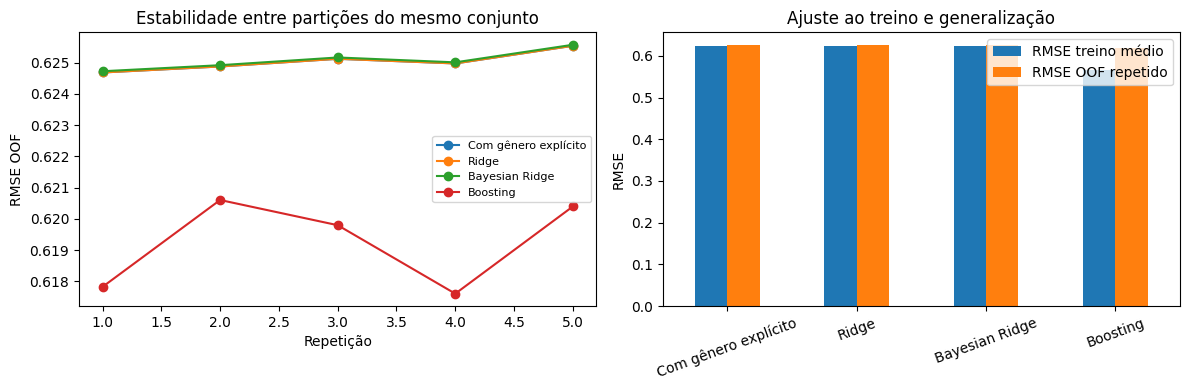

In [3]:
families = [('06','Com gênero explícito'), ('08','Ridge'), ('08','Bayesian Ridge'), ('07','Boosting')]
comparison = summarize(families)
display(comparison.round(6))
reference = record('06','Com gênero explícito')
paired_rows = []
for prefix, name in families[1:]:
    r = record(prefix, name)
    delta = np.array(r['rmse_valid']) - reference['rmse_valid']
    delta_repeat = np.array(r['rmse_repeat']) - reference['rmse_repeat']
    paired_rows.append({'candidato': name, 'diferença RMSE OOF': r['rmse_oof']-reference['rmse_oof'],
                        'partições com melhora': int((delta < 0).sum()),
                        'repetições com melhora': int((delta_repeat < 0).sum())})
display(pd.DataFrame(paired_rows).set_index('candidato'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for prefix, name in families:
    r = record(prefix, name)
    axes[0].plot(range(1, 6), r['rmse_repeat'], 'o-', label=name)
comparison[['RMSE treino médio','RMSE OOF repetido']].plot.bar(ax=axes[1], rot=20)
axes[0].set(xlabel='Repetição', ylabel='RMSE OOF', title='Estabilidade entre partições do mesmo conjunto')
axes[0].legend(fontsize=8)
axes[1].set(ylabel='RMSE', xlabel='', title='Ajuste ao treino e generalização')
plt.tight_layout();plt.show()


## 3 Diagnóstico exploratório dos erros restantes

Comparamos a regressão com gênero e boosting. Os gráficos mostram a média dos resíduos OOF por quantis, com o mesmo agrupamento para ambos. Médias e afinidade são atributos usados; contagens, idade e ano ainda não entraram nesta comparação. As contagens e os tamanhos das faixas aparecem na tabela.

Este diagnóstico procura perguntas futuras e não ajusta modelos usando os resíduos. Um padrão marginal não identifica causalidade nem garante ganho ao incluir o atributo. Ausência de padrão médio não exclui diferenças na dispersão ou interações. As faixas foram usadas apenas para visualização.

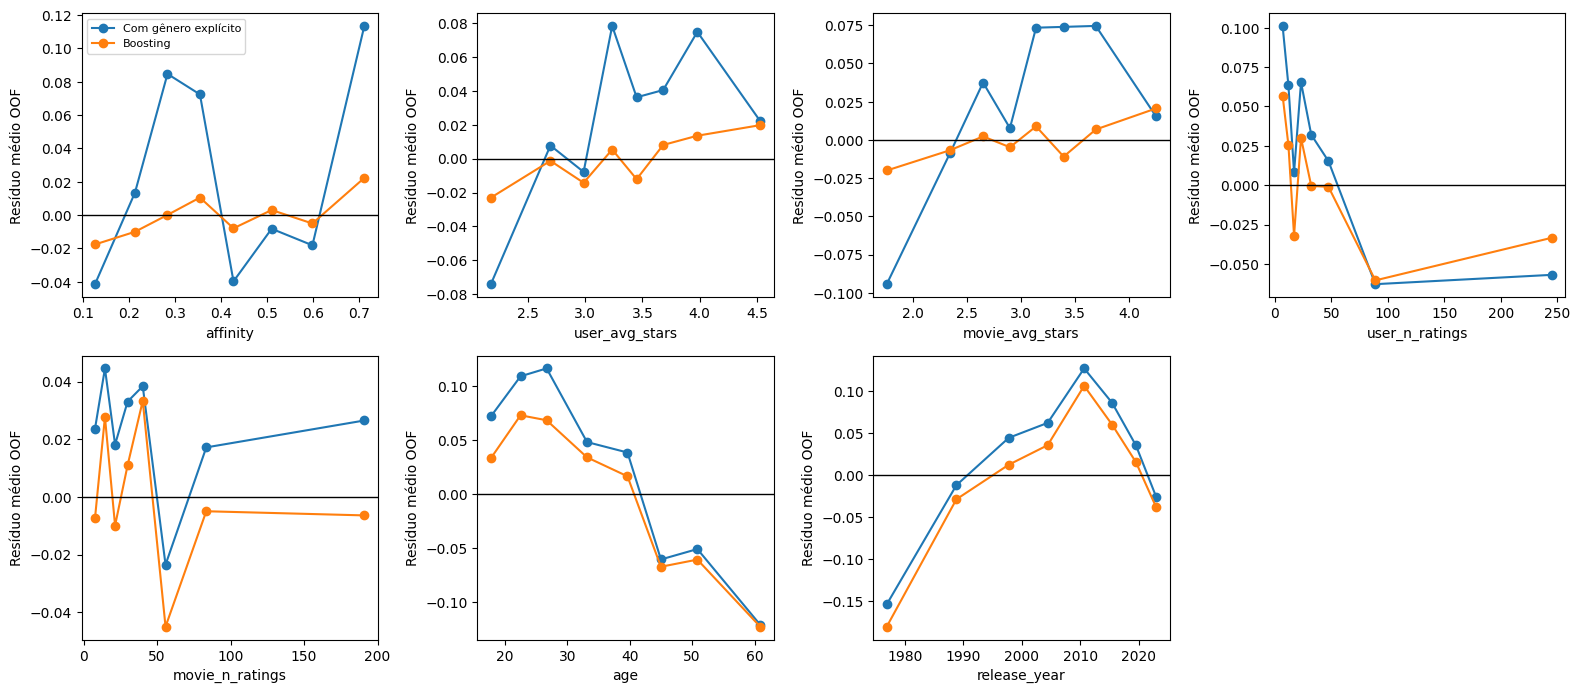

,x,resíduo,n,atributo,modelo,RMSE OOF repetido
0,0.1268,-0.0415,503,affinity,Com gênero explícito,0.6747
1,0.2135,0.0134,502,affinity,Com gênero explícito,0.6648
2,0.2841,0.0847,501,affinity,Com gênero explícito,0.6773
3,0.3545,0.0724,502,affinity,Com gênero explícito,0.6258
4,0.4274,-0.0398,496,affinity,Com gênero explícito,0.6343
...,...,...,...,...,...,...
107,2004.4332,0.0353,464,release_year,Boosting,0.6443
108,2010.6820,0.1060,610,release_year,Boosting,0.5841
109,2015.4751,0.0598,461,release_year,Boosting,0.6052
110,2019.5549,0.0152,501,release_year,Boosting,0.6058


In [4]:
df['affinity'] = np.select([df.genre.eq('action'),df.genre.eq('comedy')],
                           [df.share_action,df.share_comedy],default=df.share_drama)
diagnostic_features = ['affinity','user_avg_stars','movie_avg_stars',
                       'user_n_ratings','movie_n_ratings','age','release_year']
diagnostic_models = [('06','Com gênero explícito'), ('07','Boosting')]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
bin_rows = []
for ax, feature in zip(axes.flat, diagnostic_features):
    bins = pd.qcut(df[feature], 8, duplicates='drop')
    for prefix, name in diagnostic_models:
        pred = prediction(prefix, name)
        temp = pd.DataFrame({'x': df[feature], 'resíduo': y-pred.mean(axis=0),
                             'erro quadrático': ((pred-y)**2).mean(axis=0)})
        table = temp.groupby(bins, observed=True).agg(
            x=('x','mean'), resíduo=('resíduo','mean'), mse=('erro quadrático','mean'), n=('x','size'))
        ax.plot(table.x, table['resíduo'], 'o-', label=name)
        bin_rows.append(table.reset_index(drop=True).assign(atributo=feature, modelo=name))
    ax.axhline(0,color='black',linewidth=1)
    ax.set(xlabel=feature,ylabel='Resíduo médio OOF')
axes.flat[-1].axis('off')
axes.flat[0].legend(fontsize=8)
plt.tight_layout();plt.show()
bin_table = pd.concat(bin_rows, ignore_index=True)
bin_table['RMSE OOF repetido'] = np.sqrt(bin_table.pop('mse'))
display(bin_table.round(4))
comparison.to_csv(folder / 'comparacao_familias.csv')
bin_table.to_csv(folder / 'diagnostico_residuos.csv', index=False)


## 4 Decisão após a leitura da rodada

**A rodada inicial de seis colunas foi consolidada e seguida pelos testes finais de idade, ano e contagens.** Com nove colunas, o boosting chegou a 0,564180; ao incluir `log1p` das duas contagens, chegou a 0,544851. A receita final representa os dez atributos brutos em onze colunas numéricas. O boosting venceu nas 25 partições e nas cinco repetições; Ridge não trouxe ganho material.

O boosting reduziu os padrões marginais em afinidade e nas duas médias, mas **idade e ano de lançamento ainda exibem estrutura nos resíduos dos dois procedimentos**. Nas faixas de idade, o resíduo médio do boosting vai de aproximadamente +0,073 na faixa com média de 22,5 anos a −0,123 na faixa com média de 60,9 anos. Por lançamento, a faixa com média de 1976,9 tem resíduo −0,181, enquanto a faixa com média de 2010,7 tem +0,106. São associações exploratórias, não efeitos causais nem garantia de ganho.

### Próximas duas hipóteses propostas

1. **Idade acrescenta informação?** Comparar a referência de seis atributos com a mesma referência acrescida apenas de idade. Uma primeira hipótese simples é um termo linear padronizado na regressão. Avaliar ganho global e redução do padrão por idade. Não acrescentar ano simultaneamente.
2. **Ano de lançamento pede uma curva?** Depois de interpretar idade, testar lançamento separadamente. O padrão em arco motiva comparar a referência com um termo linear e depois com linear + quadrático, centrados no treino, mantendo todo o restante fixo. A forma proposta deve ser registrada antes da execução.

Se esses testes modificarem os atributos adotados, repetir a comparação entre regressão e boosting com o mesmo conjunto atualizado. Não comparar um boosting antigo com uma regressão que recebeu informação nova como se a diferença fosse apenas de algoritmo.

As contagens apresentaram diferenças de erro entre faixas. O teste final com seus logaritmos reduziu pouco o erro linear, mas levou o boosting de 0,564180 a 0,544851, com melhora nas 25 partições.

**Não adicionamos MLP ou Random Forest nesta rodada.** kNN foi verificado após a aula correspondente, mas ficou atrás da regressão e do boosting. Idade, ano e contagens foram testados; a exploração foi encerrada e a submissão final do boosting foi gerada após congelar a receita.

A escolha entre famílias usa os mesmos dados já explorados e pode ser otimista. Uma eventual avaliação do procedimento completo precisa incluir a seleção de família ou usar dados realmente independentes. As curvas por faixa mostram médias e não descartam outras formas de estrutura nos erros.